# CDMA / DSSS: как сигнал вытаскивается из шума

Бит $b\in\{\pm1\}$, код $c_k\in\{\pm1\}$, $N$ чипов на бит. Приём: $r_k = A\,b\,c_k + n_k$, $n_k\sim\mathcal N(0,\sigma^2)$.

Деспрединг:
$$z=\sum_k r_k c_k = A\,b\,N + \sum_k n_k c_k,\qquad \mathrm{Var}\Big(\sum n_k c_k\Big)=N\sigma^2$$

$$\mathrm{SNR}_\text{out}=\frac{(AN)^2}{N\sigma^2}=N\cdot\mathrm{SNR}_\text{chip}$$

**Сигнал растёт как $N$, шум — как $\sqrt N$.** Выигрыш обработки $G_p=10\log_{10}N$ дБ.

Параметры — в ячейке ниже, всё остальное перезапускается от них.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.special import erfc

%matplotlib inline
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3})

SEED = 1
SNR_CHIP_DB = -15.0   # SNR на чип, дБ (сигнал ниже шума)
NBITS_LFSR = 10       # N = 2^10 - 1 = 1023, как GPS C/A
JSR_DB = 20.0         # мощность глушилки относительно сигнала, дБ

rng = np.random.default_rng(SEED)

## Примитивы: m-последовательность, Gold-коды, спрединг, канал

In [2]:
def mseq(taps, nbits, seed=1):
    """m-последовательность на LFSR (Фибоначчи), выход {+1,-1}, длина 2^nbits-1."""
    state = [(seed >> i) & 1 for i in range(nbits)]
    out = []
    for _ in range(2**nbits - 1):
        out.append(state[-1])
        fb = 0
        for t in taps:
            fb ^= state[t - 1]
        state = [fb] + state[:-1]
    return 1 - 2 * np.array(out, dtype=float)

TAPS = {7: [7, 6], 10: [10, 3]}

def gold(shift, nbits=10):
    """Gold-код из преферентной пары (полиномы GPS C/A: G1=[10,3], G2=[10,9,8,6,3,2])."""
    return mseq([10, 3], nbits) * np.roll(mseq([10, 9, 8, 6, 3, 2], nbits), shift)

def spread(bits, code):
    return np.repeat(bits, len(code)) * np.tile(code, len(bits))

def despread(rx, code):
    return (rx.reshape(-1, len(code)) * code).sum(axis=1)

def awgn(x, snr_db, rng, amp=1.0):
    sigma = amp / np.sqrt(10 ** (snr_db / 10))
    return x + sigma * rng.standard_normal(len(x)), sigma

code = mseq(TAPS[NBITS_LFSR], NBITS_LFSR)
N = len(code)
print(f"N = {N}, Gp = {10*np.log10(N):.1f} дБ, SNR на чип = {SNR_CHIP_DB} дБ "
      f"→ ожидаемый SNR после деспрединга ≈ {SNR_CHIP_DB + 10*np.log10(N):.1f} дБ")

N = 1023, Gp = 30.1 дБ, SNR на чип = -15.0 дБ → ожидаемый SNR после деспрединга ≈ 15.1 дБ


## 1. Временная область
Три бита, каждый размазан на $N$ чипов. В принятом сигнале чипов не видно — шум в ~5.6 раза больше по амплитуде. Сумма по коду восстанавливает знак.

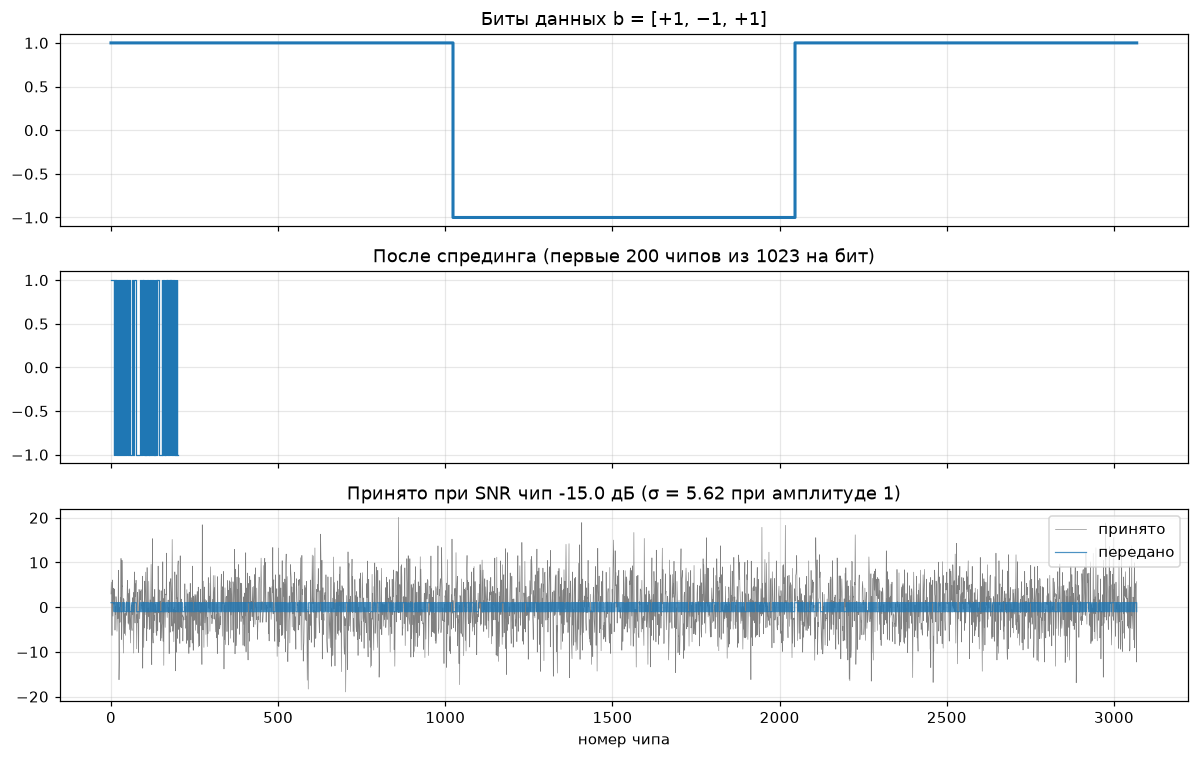

z     = [1334 -923 1108]   (ожидание ±N = ±1023, σ шума = √N·σ = 180)
b_hat = [ 1 -1  1]


In [3]:
bits = np.array([1.0, -1.0, 1.0])
tx = spread(bits, code)
rx, sigma = awgn(tx, SNR_CHIP_DB, rng)
z = despread(rx, code)

t = np.arange(3 * N)
fig, ax = plt.subplots(3, 1, figsize=(11, 7), sharex=True)
ax[0].step(t, np.repeat(bits, N), where="post", lw=2); ax[0].set_title("Биты данных b = [+1, −1, +1]")
ax[1].step(t[:200], tx[:200], where="post", lw=0.8); ax[1].set_title(f"После спрединга (первые 200 чипов из {N} на бит)")
ax[2].plot(t, rx, lw=0.4, color="gray", label="принято")
ax[2].step(t, tx, where="post", lw=0.8, alpha=0.8, label="передано")
ax[2].set_title(f"Принято при SNR чип {SNR_CHIP_DB} дБ (σ = {sigma:.2f} при амплитуде 1)")
ax[2].set_xlabel("номер чипа"); ax[2].legend(loc="upper right")
plt.tight_layout(); plt.show()

print("z     =", np.round(z).astype(int), f"  (ожидание ±N = ±{N}, σ шума = √N·σ = {np.sqrt(N)*sigma:.0f})")
print("b_hat =", np.sign(z).astype(int))

## 2. Корреляция по сдвигу кода (захват)
Автокорреляция m-последовательности: $R(0)=N$, $R(\tau\ne0)=-1$. Приёмник не знает фазу кода — перебирает все сдвиги через FFT (так делают в GPS-приёмниках). Пик над шумом в $\approx\sqrt{N\cdot\mathrm{SNR_{chip}}}$ σ.

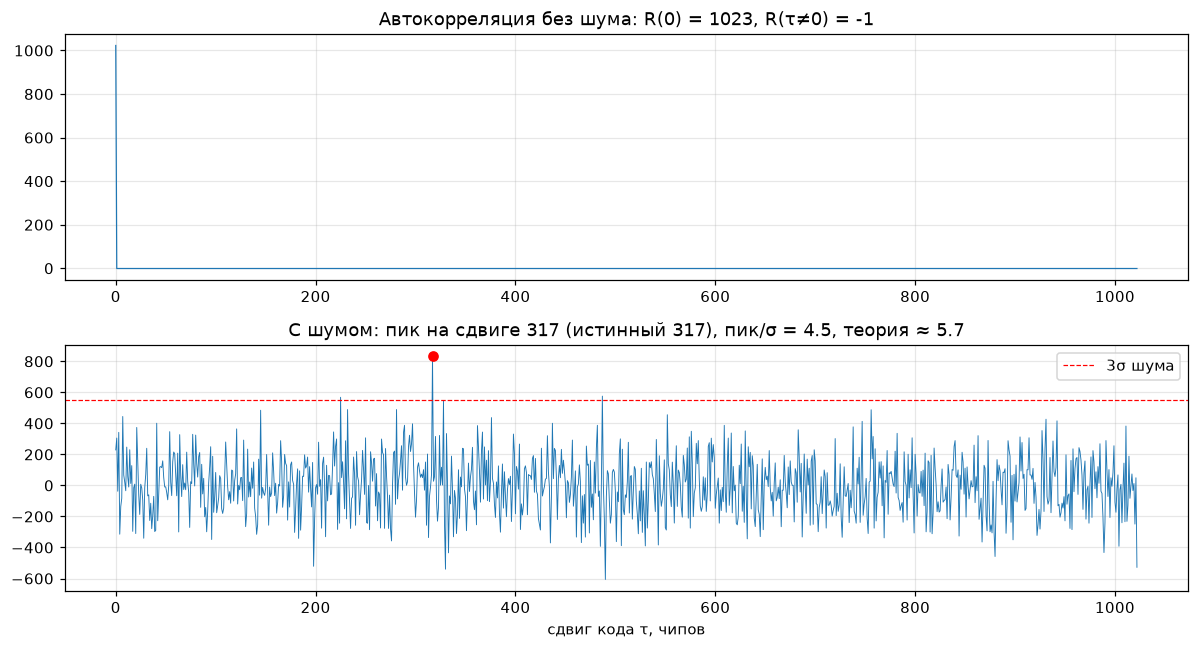

In [4]:
true_shift = 317
rx, _ = awgn(np.roll(code, true_shift), SNR_CHIP_DB, rng)
xcorr = lambda a, b: np.real(np.fft.ifft(np.fft.fft(a) * np.conj(np.fft.fft(b))))
corr, clean = xcorr(rx, code), xcorr(code, code)

pk = np.argmax(corr)
floor = np.std(np.delete(corr, pk))
fig, ax = plt.subplots(2, 1, figsize=(11, 6))
ax[0].plot(clean, lw=0.8)
ax[0].set_title(f"Автокорреляция без шума: R(0) = {clean[0]:.0f}, R(τ≠0) = {np.median(clean[1:]):.0f}")
ax[1].plot(corr, lw=0.6); ax[1].plot(pk, corr[pk], "ro")
ax[1].axhline(3 * floor, color="r", ls="--", lw=0.8, label="3σ шума")
ax[1].set_title(f"С шумом: пик на сдвиге {pk} (истинный {true_shift}), пик/σ = {corr[pk]/floor:.1f}, "
                f"теория ≈ {np.sqrt(N * 10**(SNR_CHIP_DB/10)):.1f}")
ax[1].set_xlabel("сдвиг кода τ, чипов"); ax[1].legend()
plt.tight_layout(); plt.show()

На −15 дБ пик едва над 3σ — на практике захват делают накоплением нескольких периодов кода (GPS: 1–20 мс когерентно + некогерентное накопление).

## 3. Распределение решающей статистики
Слева — решение по одному чипу (почти монетка). Справа — $z/N$: среднее $\pm1$, СКО ужалось в $\sqrt N$ раз.

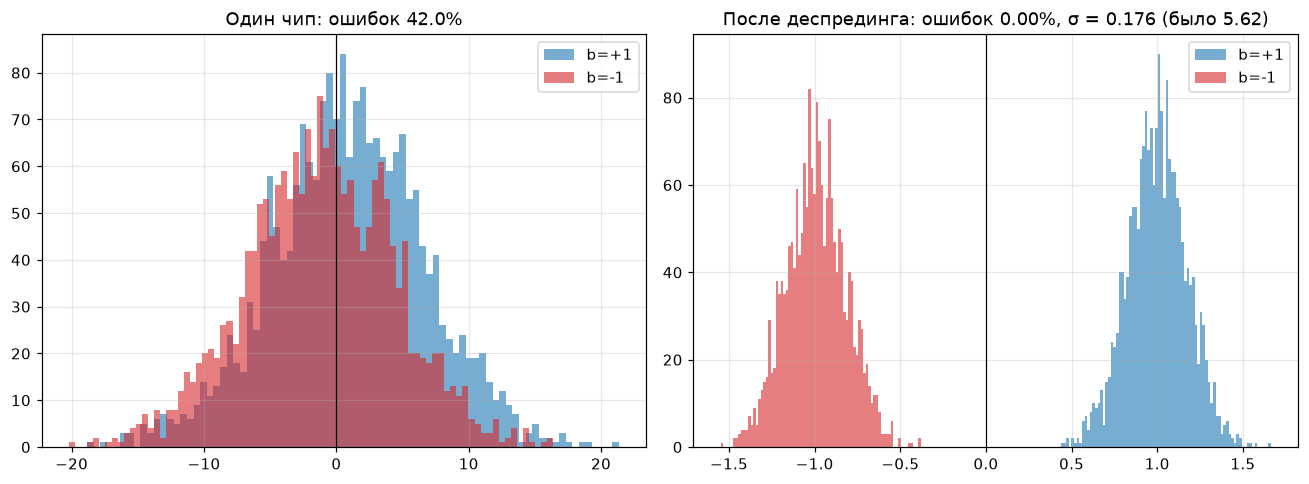

In [5]:
nb = 4000
bits = rng.choice([-1.0, 1.0], nb)
rx, sigma = awgn(spread(bits, code), SNR_CHIP_DB, rng)
one_chip = rx.reshape(-1, N)[:, 0] * code[0]
zn = despread(rx, code) / N

fig, ax = plt.subplots(1, 2, figsize=(12, 4.5))
for b, c in [(1, "C0"), (-1, "C3")]:
    ax[0].hist(one_chip[bits == b], 80, alpha=0.6, color=c, label=f"b={b:+d}")
    ax[1].hist(zn[bits == b], 80, alpha=0.6, color=c, label=f"b={b:+d}")
ax[0].set_title(f"Один чип: ошибок {np.mean(np.sign(one_chip) != bits):.1%}")
ax[1].set_title(f"После деспрединга: ошибок {np.mean(np.sign(zn) != bits):.2%}, σ = {sigma/np.sqrt(N):.3f} (было {sigma:.2f})")
for a in ax: a.axvline(0, color="k", lw=0.8); a.legend()
plt.tight_layout(); plt.show()

## 4. Узкополосная помеха (глушилка)
Тон с мощностью на `JSR_DB` выше сигнала. Умножение на код в приёмнике: свой сигнал **сворачивается** в полосу бита, помеха **разворачивается** на всю полосу кода. После ФНЧ (суммирования за бит) от помехи остаётся ~$1/N$.

Все спектры нормированы на одну опорную величину — пик помехи до деспрединга.

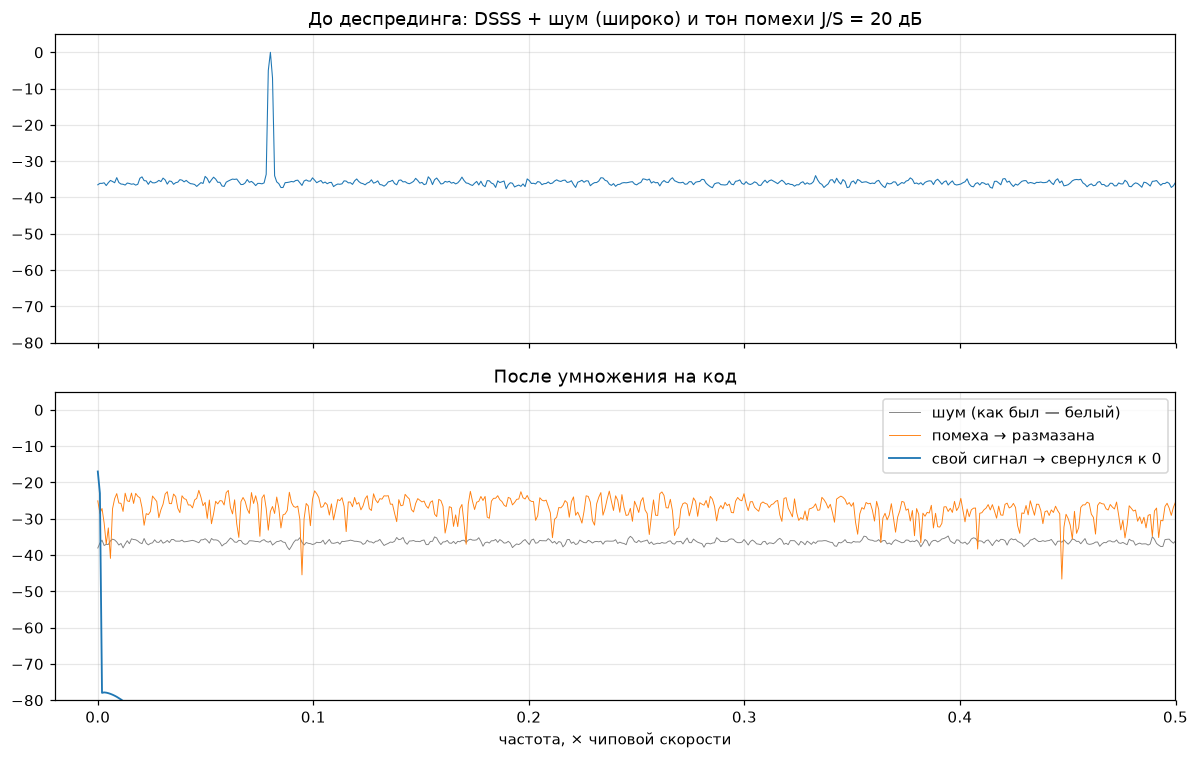

J/S на входе: 20.0 дБ → после интегратора: -7.8 дБ (подавление 27.8 дБ, теория 10·log10(N) = 30.1)
BER при J/S = 20 дБ после деспрединга: 0.000


In [6]:
nb, sps = 64, 4
bits = rng.choice([-1.0, 1.0], nb)
tx = np.repeat(spread(bits, code), sps)
n = np.arange(len(tx))
J = np.sqrt(2 * 10 ** (JSR_DB / 10)) * np.cos(2 * np.pi * 0.02 * n)
noise = (1 / np.sqrt(10 ** (SNR_CHIP_DB / 10))) * rng.standard_normal(len(tx))
code_up = np.tile(np.repeat(code, sps), nb)

def psd(x, seg=4096):
    x = x[: len(x) // seg * seg].reshape(-1, seg) * np.hanning(seg)
    return np.fft.rfftfreq(seg) * sps, np.mean(np.abs(np.fft.rfft(x, axis=1)) ** 2, axis=0)

f, P_rx = psd(tx + J + noise)
ref = P_rx.max()
dB = lambda P: 10 * np.log10(P / ref + 1e-20)
_, P_sig = psd(tx * code_up); _, P_j = psd(J * code_up); _, P_n = psd(noise * code_up)

fig, ax = plt.subplots(2, 1, figsize=(11, 7), sharex=True)
ax[0].plot(f, dB(P_rx), lw=0.7)
ax[0].set_title(f"До деспрединга: DSSS + шум (широко) и тон помехи J/S = {JSR_DB:.0f} дБ")
ax[1].plot(f, dB(P_n), lw=0.6, color="gray", label="шум (как был — белый)")
ax[1].plot(f, dB(P_j), lw=0.6, color="C1", label="помеха → размазана")
ax[1].plot(f, dB(P_sig), lw=1.2, color="C0", label="свой сигнал → свернулся к 0")
ax[1].set_title("После умножения на код")
ax[1].set_xlabel("частота, × чиповой скорости"); ax[1].legend(loc="upper right")
for a in ax: a.set_ylim(-80, 5)
ax[1].set_xlim(-0.02, 0.5)
plt.tight_layout(); plt.show()

z = despread((tx + J + noise)[::sps], code)
zJ = despread(J[::sps], code) / N          # вклад помехи в z/N (сигнал даёт ±1)
print(f"J/S на входе: {JSR_DB:.1f} дБ → после интегратора: {10*np.log10(np.mean(zJ**2)):.1f} дБ "
      f"(подавление {JSR_DB - 10*np.log10(np.mean(zJ**2)):.1f} дБ, теория 10·log10(N) = {10*np.log10(N):.1f})")
print(f"BER при J/S = {JSR_DB:.0f} дБ после деспрединга: {np.mean(np.sign(z) != bits):.3f}")

## 5. Два абонента в одной полосе
Gold-коды (как GPS C/A): взаимная корреляция $|R_{12}|\le 65 \ll N=1023$. Каждый приёмник видит чужой сигнал как добавку к шуму.

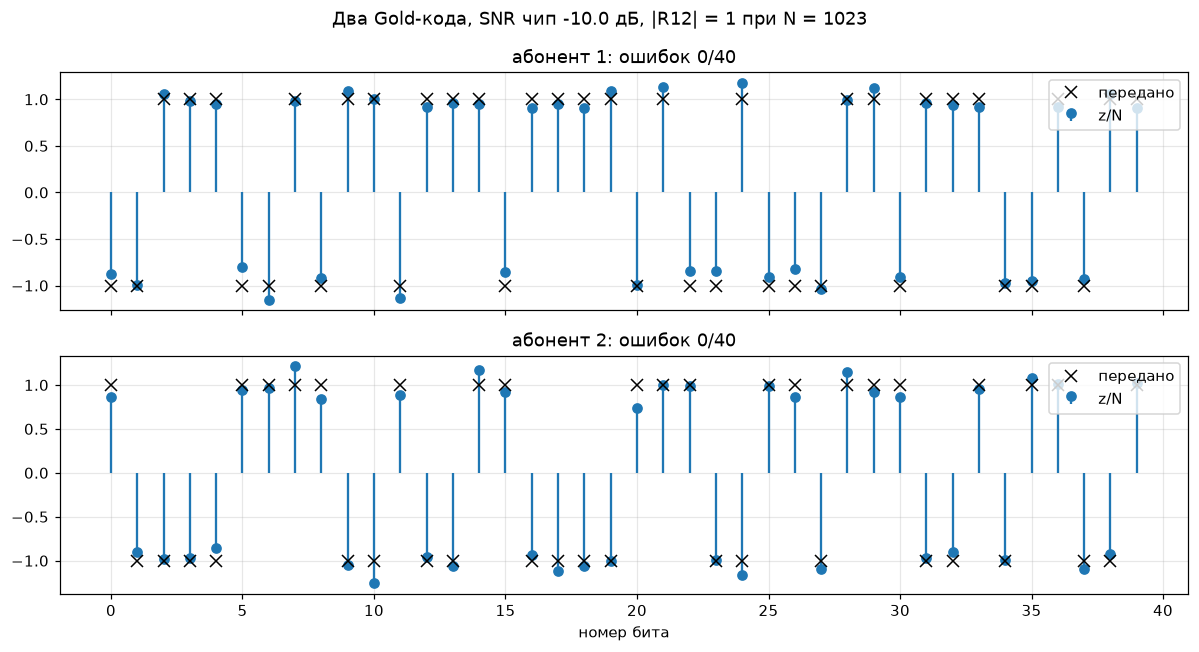

In [7]:
c1, c2 = gold(5), gold(200)
nb = 40
b1, b2 = rng.choice([-1.0, 1.0], nb), rng.choice([-1.0, 1.0], nb)
snr = SNR_CHIP_DB + 5
rx, _ = awgn(spread(b1, c1) + spread(b2, c2), snr, rng)
z1, z2 = despread(rx, c1) / N, despread(rx, c2) / N

fig, ax = plt.subplots(2, 1, figsize=(11, 6), sharex=True)
for a, zz, b, name in [(ax[0], z1, b1, "абонент 1"), (ax[1], z2, b2, "абонент 2")]:
    a.stem(zz, basefmt=" ", label="z/N"); a.plot(b, "kx", ms=8, label="передано")
    a.set_title(f"{name}: ошибок {int(np.sum(np.sign(zz) != b))}/{nb}"); a.legend(loc="upper right")
ax[1].set_xlabel("номер бита")
fig.suptitle(f"Два Gold-кода, SNR чип {snr} дБ, |R12| = {abs(np.sum(c1*c2)):.0f} при N = {N}")
plt.tight_layout(); plt.show()

## 6. BER: важная оговорка
$E_b/N_0 = N\cdot\mathrm{SNR_{chip}}/2$ (вещественный шум: $N_0/2=\sigma^2$). Против белого шума CDMA **ничего не выигрывает** — кривая совпадает с обычной BPSK. Выигрыш в том, что при этом SNR на чип глубоко отрицательный: сигнал не виден на спектре, и узкополосные помехи давятся в $N$ раз.

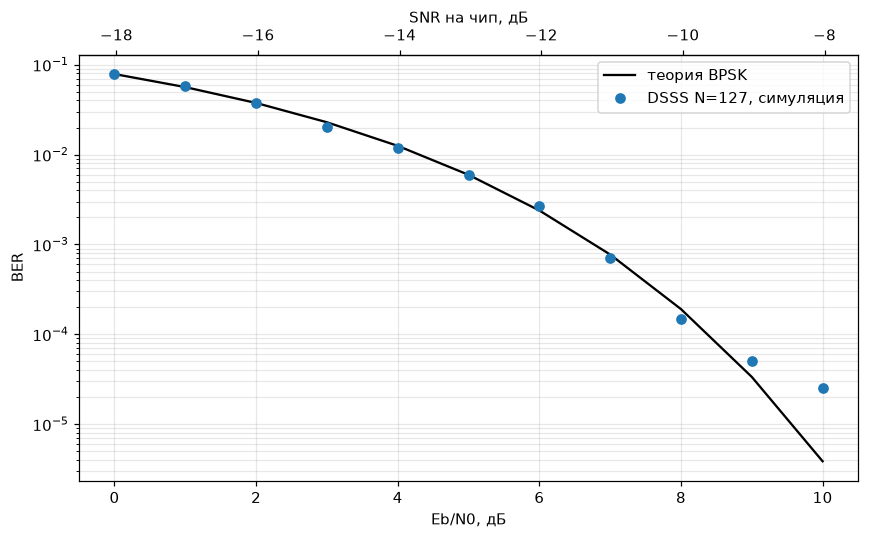

In [8]:
code127 = mseq(TAPS[7], 7)  # короче — быстрее считать, BER от N не зависит
N7 = len(code127)
ebn0 = np.arange(0, 11)
sim = []
for e in ebn0:
    errs = 0
    for _ in range(10):
        b = rng.choice([-1.0, 1.0], 2000)
        rx, _ = awgn(spread(b, code127), e + 10*np.log10(2) - 10 * np.log10(N7), rng)
        errs += np.sum(np.sign(despread(rx, code127)) != b)
    sim.append(max(errs, 0.5) / 20000)

fig, ax = plt.subplots(figsize=(8, 5))
ax.semilogy(ebn0, 0.5 * erfc(np.sqrt(10 ** (ebn0 / 10))), "k-", label="теория BPSK")
ax.semilogy(ebn0, sim, "o", label=f"DSSS N={N7}, симуляция")
top = ax.secondary_xaxis("top", functions=(lambda x: x + 10*np.log10(2) - 10*np.log10(N7), lambda x: x - 10*np.log10(2) + 10*np.log10(N7)))
top.set_xlabel("SNR на чип, дБ")
ax.set_xlabel("Eb/N0, дБ"); ax.set_ylabel("BER"); ax.grid(which="both", alpha=0.3); ax.legend()
plt.tight_layout(); plt.show()

## Что покрутить
- `SNR_CHIP_DB` → −20…−25 дБ: при N=1023 ошибки начинают появляться около −25 дБ
- `NBITS_LFSR = 7` (N=127): выигрыш 21 дБ вместо 30 — видно, как всё ухудшается
- `JSR_DB` → 30–35 дБ: помеха начинает пробивать, предел ≈ Gp минус нужный запас по Eb/N0